# 01 — Análise exploratória: X-Wines

Estatísticas descritivas e gráficos da base (slide **c**) e efeito do tratamento de dados (slide **e**).
As figuras são salvas em `slides/figs/` para usar no PPT.

Base: de Azambuja, Morais & Filipe (2023), *X-Wines: A Wine Dataset for Recommender Systems and Machine Learning*, Big Data Cogn. Comput. 7(1), 20. Licença CC0.

In [1]:
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data import PROCESSED_DIR, build_dataset, find_files, load_processed, sparsity
from src.split import RELEVANT_RATING

FIGS = ROOT / "slides" / "figs"
FIGS.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGS / f"{name}.png", bbox_inches="tight")

def top_counts(series_of_lists, n=20):
    return pd.Series(Counter(x for l in series_of_lists for x in l)).nlargest(n)

## 1. Carga e tratamento
Na primeira execução roda o pipeline completo (`src/data.py`) e salva em `data/processed/`; depois só lê os parquets.

In [2]:
print("Arquivos:", *[p.name for p in find_files()])
if (PROCESSED_DIR / "ratings.parquet").exists():
    data = load_processed()
else:
    data = build_dataset()

items, ratings_all, ratings = data["items"], data["ratings_all"], data["ratings"]
data["log"]

Arquivos: XWines_Slim_1K_wines.csv XWines_Slim_150K_ratings.csv


,tabela,passo,linhas,repetidas,usuarios,vinhos
0,vinhos,original,1007,NaN,NaN,NaN
1,vinhos,remove WineID duplicado,1007,NaN,NaN,NaN
2,vinhos,remove sem nome/tipo/uva,1007,NaN,NaN,NaN
3,vinhos,"remove teor alcoólico fora de 0,5–25%",999,NaN,NaN,NaN
4,notas,original,150000,NaN,NaN,NaN
5,notas,remove ausentes/fora da escala 1–5,150000,NaN,NaN,NaN
6,notas,remove par usuário–vinho repetido (outras safras),150000,0.0,NaN,NaN
7,notas,remove vinhos excluídos na limpeza,149945,NaN,NaN,NaN
8,notas,"k-core (usuário ≥ 5, vinho ≥ 5)",149315,NaN,10252.0,924.0


## 2. Visão geral

In [3]:
def overview(df, name):
    users, its = df["user_id"].nunique(), df["item_id"].nunique()
    return pd.Series({
        "notas": len(df), "usuários": users, "vinhos": its,
        "notas/usuário (média)": len(df) / users, "notas/vinho (média)": len(df) / its,
        "nota média": df["rating"].mean(), "esparsidade": f"{sparsity(df):.4%}",
    }, name=name)

pd.concat([overview(ratings_all, "após limpeza"), overview(ratings, "após k-core")], axis=1)

,após limpeza,após k-core
notas,149945,149315
usuários,10555,10252
vinhos,999,924
notas/usuário (média),14.206063,14.564475
notas/vinho (média),150.095095,161.59632
nota média,3.819824,3.818826
esparsidade,98.5780%,98.4238%


In [4]:
print(f"Catálogo limpo: {len(items):,} vinhos de {items['country'].nunique()} países, "
      f"{items['winery'].nunique():,} vinícolas, {items['region'].nunique():,} regiões")
print(f"Período das notas: {ratings_all['date'].min():%Y-%m} a {ratings_all['date'].max():%Y-%m}")
items[["abv", "n_grapes", "n_vintages"]].describe().round(2)

Catálogo limpo: 999 vinhos de 31 países, 786 vinícolas, 322 regiões
Período das notas: 2012-04 a 2021-12


,abv,n_grapes,n_vintages
count,999.00,999.00,999.00
mean,13.10,1.58,30.11
std,1.83,1.10,15.73
min,4.00,1.00,1.00
25%,12.50,1.00,19.00
50%,13.00,1.00,27.00
75%,14.00,2.00,39.00
max,21.00,9.00,72.00


## 3. Distribuição das notas
Escala de 1 a 5 em passos de 0,5. O limiar de **relevância** (vinho de que o usuário gostou) sai daqui.

notas ≥ 4.0: 58.4%
notas ≥ 4.5: 22.4%
notas ≥ 5.0: 7.6%


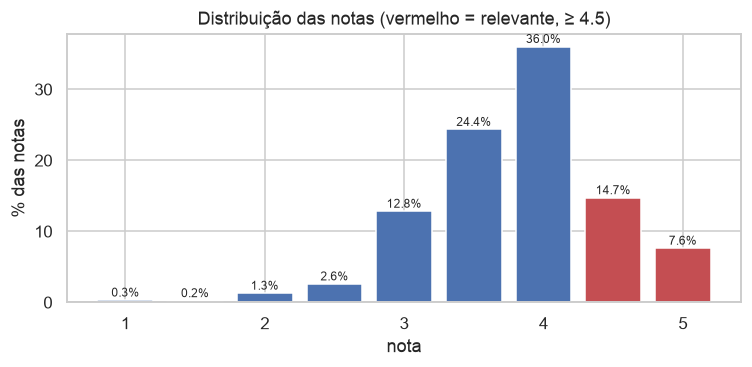

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
dist = ratings_all["rating"].value_counts(normalize=True).sort_index() * 100
ax.bar(dist.index, dist.values, width=0.4, color=["C3" if r >= RELEVANT_RATING else "C0" for r in dist.index])
for x, y in zip(dist.index, dist.values):
    ax.text(x, y + 0.5, f"{y:.1f}%", ha="center", fontsize=8)
ax.set(xlabel="nota", ylabel="% das notas", title=f"Distribuição das notas (vermelho = relevante, ≥ {RELEVANT_RATING})")
save(fig, "dist_notas")
for t in [4.0, 4.5, 5.0]:
    print(f"notas ≥ {t}: {(ratings_all['rating'] >= t).mean():.1%}")

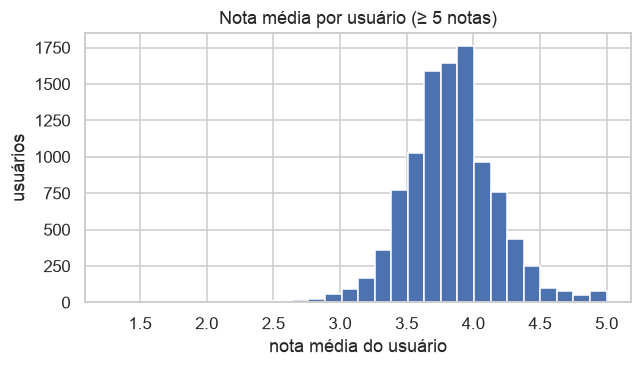

In [6]:
user_mean = ratings_all.groupby("user_id")["rating"].agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(user_mean.loc[user_mean["count"] >= 5, "mean"], bins=30)
ax.set(xlabel="nota média do usuário", ylabel="usuários", title="Nota média por usuário (≥ 5 notas)")
save(fig, "media_por_usuario")

## 4. Esparsidade e cauda longa

usuários com < 5 notas: 2.9%
vinhos com < 5 notas: 6.0%


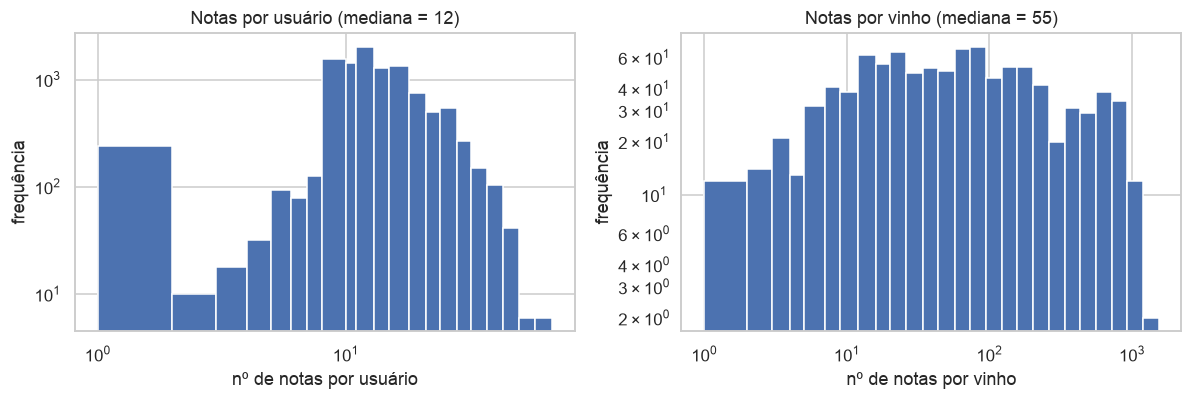

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, label in [(axes[0], "user_id", "usuário"), (axes[1], "item_id", "vinho")]:
    counts = ratings_all[col].value_counts()
    ax.hist(counts, bins=np.unique(np.logspace(0, np.log10(counts.max() + 1), 30).astype(int)))
    ax.set(xscale="log", yscale="log", xlabel=f"nº de notas por {label}", ylabel="frequência",
           title=f"Notas por {label} (mediana = {counts.median():.0f})")
save(fig, "notas_por_usuario_vinho")
for col, label in [("user_id", "usuários"), ("item_id", "vinhos")]:
    c = ratings_all[col].value_counts()
    print(f"{label} com < 5 notas: {(c < 5).mean():.1%}")

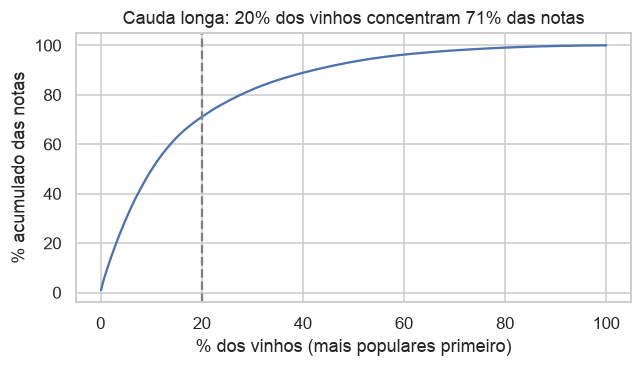

In [8]:
counts = ratings_all["item_id"].value_counts().values
cum = np.cumsum(counts) / counts.sum()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum * 100)
p20 = cum[int(len(cum) * 0.2)] * 100
ax.axvline(20, ls="--", c="gray")
ax.set(xlabel="% dos vinhos (mais populares primeiro)", ylabel="% acumulado das notas",
       title=f"Cauda longa: 20% dos vinhos concentram {p20:.0f}% das notas")
save(fig, "cauda_longa")

## 5. Evolução temporal

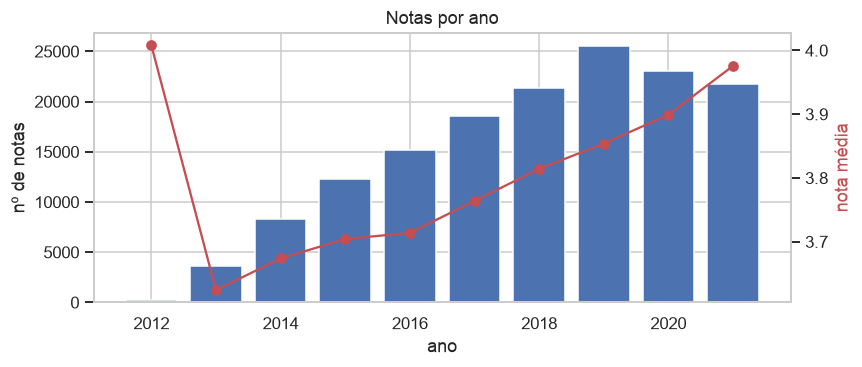

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
by_year = ratings_all.set_index("date").resample("YE")["rating"].agg(["count", "mean"])
ax.bar(by_year.index.year, by_year["count"], color="C0")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set(xlabel="ano", ylabel="nº de notas", title="Notas por ano")
ax2 = ax.twinx()
ax2.plot(by_year.index.year, by_year["mean"], color="C3", marker="o")
ax2.set_ylabel("nota média", color="C3")
ax2.grid(False)
save(fig, "notas_por_ano")

## 6. Atributos dos vinhos (base do modelo de conteúdo)

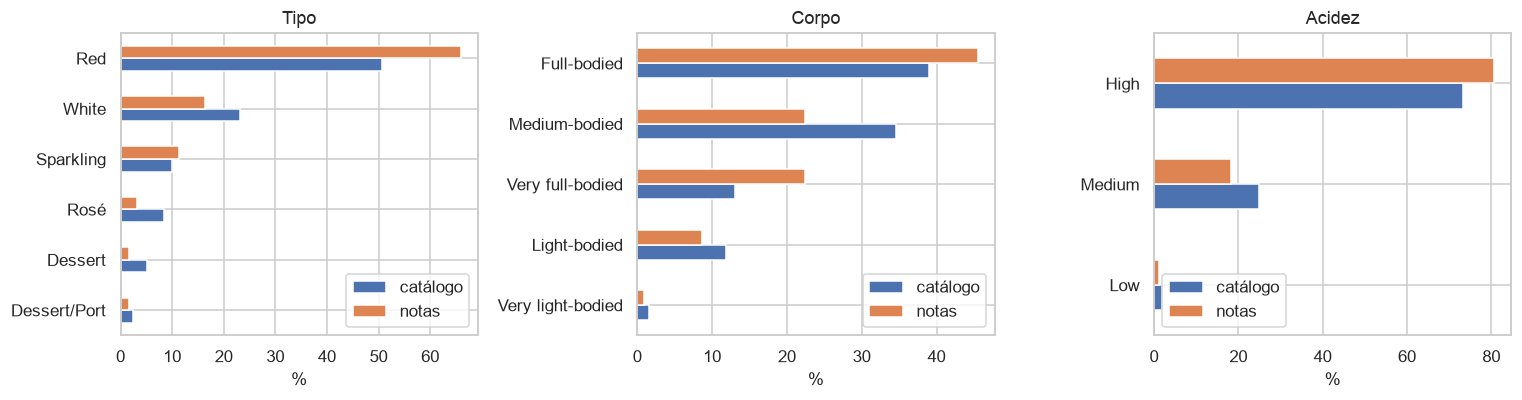

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, ["type", "body", "acidity"]):
    cat = items[col].value_counts(normalize=True) * 100
    rated = ratings_all.merge(items[["item_id", col]], on="item_id")[col].value_counts(normalize=True) * 100
    pd.DataFrame({"catálogo": cat, "notas": rated}).sort_values("catálogo").plot.barh(ax=ax)
    ax.set(title={"type": "Tipo", "body": "Corpo", "acidity": "Acidez"}[col], xlabel="%", ylabel="")
save(fig, "tipo_corpo_acidez")

187 uvas, 46 harmonizações distintas


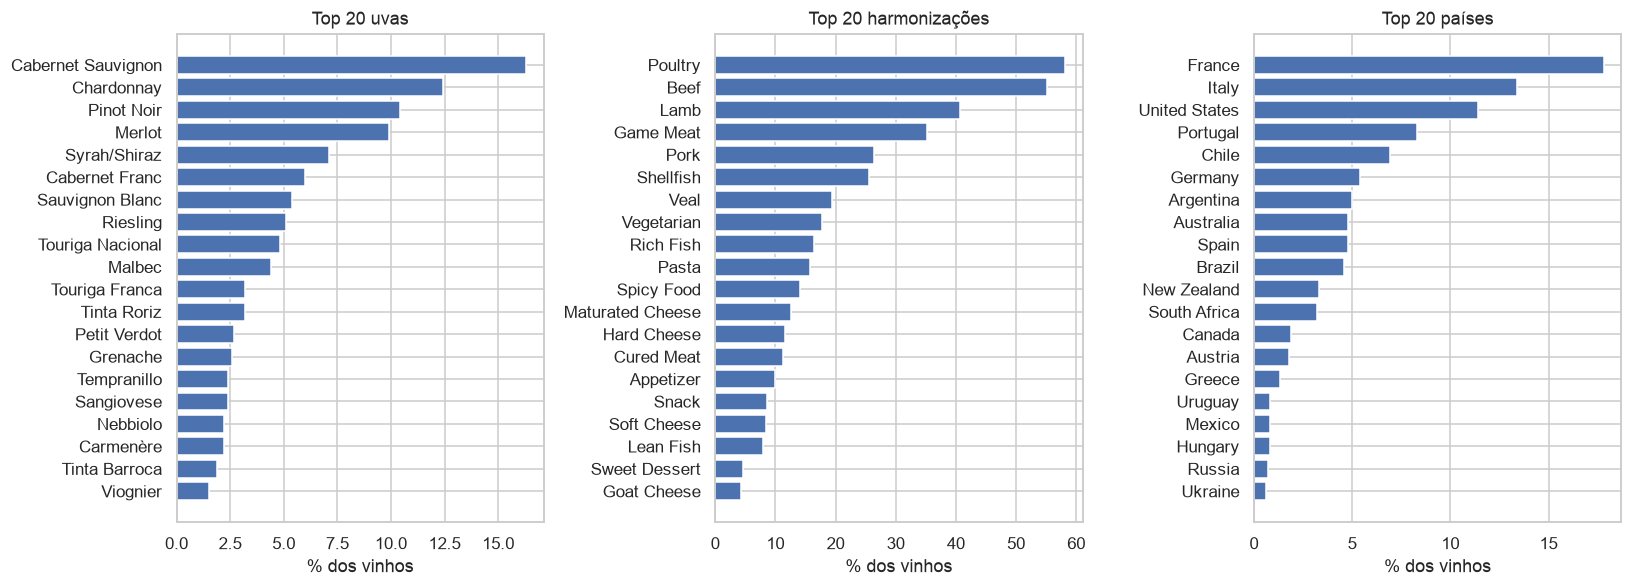

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, s, title in [(axes[0], top_counts(items["grapes"]), "Top 20 uvas"),
                     (axes[1], top_counts(items["harmonize"]), "Top 20 harmonizações"),
                     (axes[2], items["country"].value_counts().head(20), "Top 20 países")]:
    s = s.sort_values() / len(items) * 100
    ax.barh(s.index, s.values)
    ax.set(xlabel="% dos vinhos", title=title)
save(fig, "top_uvas_harmonizacao_paises")
print(f"{items['grapes'].explode().nunique()} uvas, {items['harmonize'].explode().nunique()} harmonizações distintas")

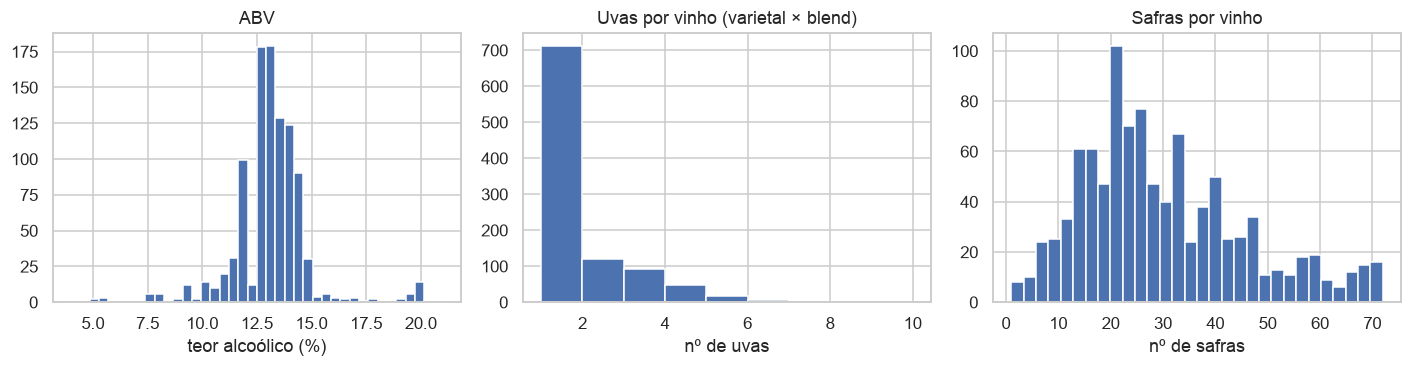

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(items["abv"], bins=40)
axes[0].set(xlabel="teor alcoólico (%)", title="ABV")
axes[1].hist(items["n_grapes"], bins=range(1, items["n_grapes"].max() + 2))
axes[1].set(xlabel="nº de uvas", title="Uvas por vinho (varietal × blend)")
axes[2].hist(items["n_vintages"], bins=30)
axes[2].set(xlabel="nº de safras", title="Safras por vinho")
save(fig, "dist_atributos")

## 7. Atributos × nota

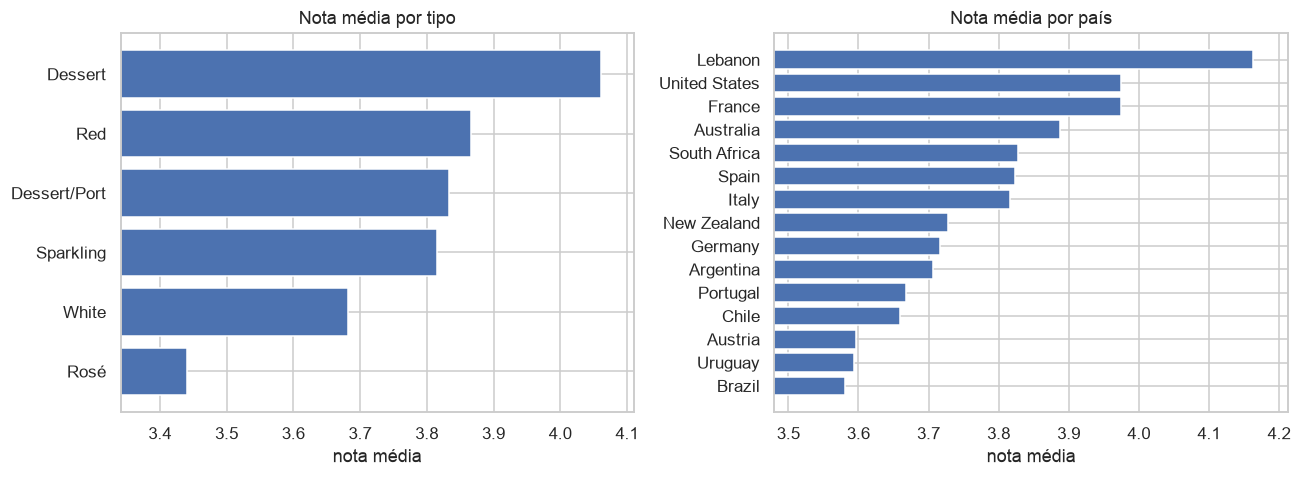

In [13]:
rated = ratings_all.merge(items, on="item_id")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, min_n in [(axes[0], "type", 1), (axes[1], "country", 500)]:
    g = rated.groupby(col)["rating"].agg(["mean", "count"])
    g = g[g["count"] >= min(min_n, g["count"].max())].sort_values("mean").tail(15)
    ax.barh(g.index, g["mean"])
    ax.set(xlim=(g["mean"].min() - 0.1, g["mean"].max() + 0.05), xlabel="nota média",
           title=f"Nota média por {'tipo' if col == 'type' else 'país'}")
save(fig, "nota_por_tipo_pais")

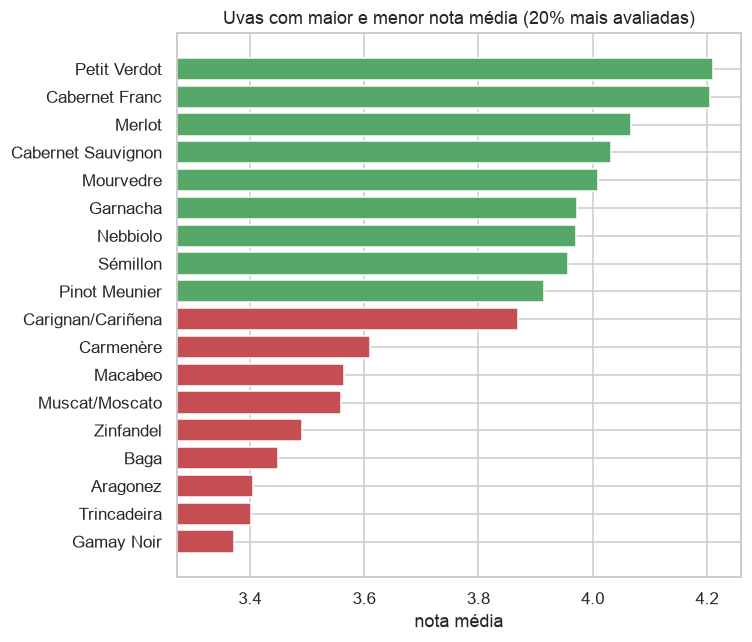

In [14]:
g = rated.explode("grapes").groupby("grapes")["rating"].agg(["mean", "count"])
g = g[g["count"] >= g["count"].quantile(0.8)]
sel = pd.concat([g.nlargest(10, "mean"), g.nsmallest(10, "mean")]).drop_duplicates().sort_values("mean")
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(sel.index, sel["mean"], color=["C3"] * (len(sel) // 2) + ["C2"] * (len(sel) - len(sel) // 2))
ax.set(xlim=(sel["mean"].min() - 0.1, sel["mean"].max() + 0.05), xlabel="nota média",
       title="Uvas com maior e menor nota média (20% mais avaliadas)")
save(fig, "nota_por_uva")

Idade do vinho no momento da avaliação (ano da nota − safra): vinhos mais velhos tendem a ser rótulos de guarda, normalmente mais bem avaliados.

Notas sem safra (N.V.) ou fora de 0–40 anos: 6.9%


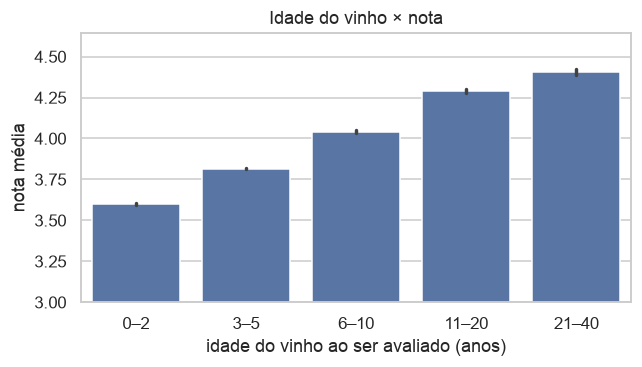

In [15]:
age = rated.assign(vintage_num=pd.to_numeric(rated["vintage"], errors="coerce"))
age["idade"] = age["date"].dt.year - age["vintage_num"]
age = age[age["idade"].between(0, 40)]
age["faixa"] = pd.cut(age["idade"], [-1, 2, 5, 10, 20, 40], labels=["0–2", "3–5", "6–10", "11–20", "21–40"])
print(f"Notas sem safra (N.V.) ou fora de 0–40 anos: {1 - len(age) / len(rated):.1%}")
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.barplot(data=age, x="faixa", y="rating", errorbar=("ci", 95), ax=ax)
ax.set(xlabel="idade do vinho ao ser avaliado (anos)", ylabel="nota média", ylim=(3, None),
       title="Idade do vinho × nota")
save(fig, "idade_vs_nota")

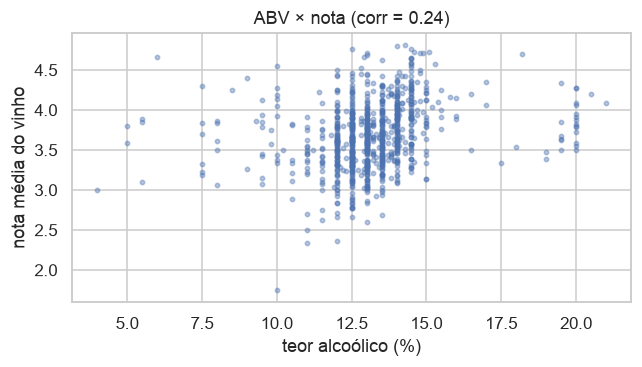

In [16]:
fig, ax = plt.subplots(figsize=(6, 3.5))
m = rated.groupby("item_id").agg(abv=("abv", "first"), nota=("rating", "mean"), n=("rating", "size"))
m = m[m["n"] >= 5]
ax.scatter(m["abv"], m["nota"], s=8, alpha=0.4)
ax.set(xlabel="teor alcoólico (%)", ylabel="nota média do vinho", title=f"ABV × nota (corr = {m['abv'].corr(m['nota']):.2f})")
save(fig, "abv_vs_nota")

## 8. Efeito do k-core
O k-core mantém um núcleo denso para treinar e avaliar. Usuários e vinhos que ficam de fora são candidatos naturais aos cenários de **usuário novo** e **item novo**.

Vinhos do catálogo fora do k-core: 75


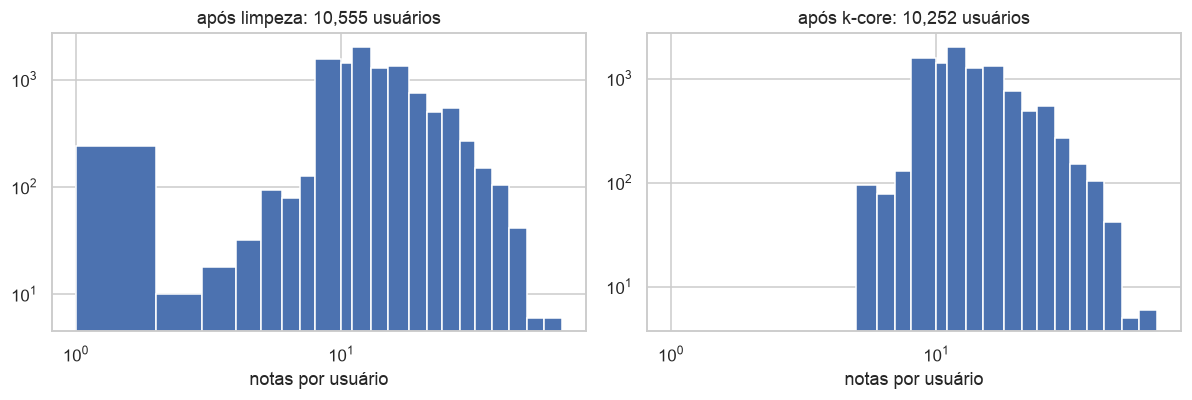

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (df, name) in zip(axes, [(ratings_all, "após limpeza"), (ratings, "após k-core")]):
    c = df["user_id"].value_counts()
    ax.hist(c, bins=np.unique(np.logspace(0, np.log10(c.max() + 1), 30).astype(int)))
    ax.set(xscale="log", yscale="log", xlabel="notas por usuário", title=f"{name}: {len(c):,} usuários")
save(fig, "efeito_kcore")
print(f"Vinhos do catálogo fora do k-core: {len(set(items['item_id']) - set(ratings['item_id'])):,}")